# 22. Chemistry: activation energy from an Arrhenius plot

**Track:** advanced example &nbsp;·&nbsp; **Uses:** Chapters 11, 12 and 13

**Reading:** Taylor, ch. 8.6 · Bevington & Robinson, ch. 6 · Krug, Hunter &
Grieger (1976)

The temperature dependence of a rate constant is summarised by the
Arrhenius equation

$$ k = A\,e^{-E_\mathrm{a}/RT} . $$

The same analysis applies to any thermally activated quantity:
diffusion coefficients, viscosities, ionic conductivities, vapour
pressures (Clausius–Clapeyron), equilibrium constants (van 't Hoff). In all
of them two parameters are extracted from data covering a narrow range of
$1/T$, and the two parameters turn out to be almost perfectly correlated.
This makes the Arrhenius plot the best-known example of why fit
parameters must not be treated as independent.

The example shows

* the correct weights for the logarithmic fit;
* why $E_\mathrm{a}$ is well determined and $A$ is not;
* that a rate constant predicted from $A \pm u_A$ and
  $E_\mathrm{a} \pm u_{E}$ without their covariance has an absurd
  uncertainty;
* a parametrisation that removes the problem;
* how the correlation produces an apparent "compensation effect".

The data are simulated from $E_\mathrm{a} = 80.0$ kJ/mol and
$A = 1.0\times10^{11}$ s⁻¹, with a relative standard uncertainty of 5 % on
every rate constant.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

try:
    import errprop as ep
except ImportError:          # running from a clone without `pip install -e .`
    import sys
    sys.path.insert(0, "../..")
    import errprop as ep

ep.use_style()
rng = np.random.default_rng(24)
R = 8.314462618            # J / (mol K)

In [2]:
Ea_true, A_true, rel_k = 80.0e3, 1.0e11, 0.05
T = np.arange(300.0, 351.0, 10.0)                      # K

def experiment():
    """Rate constants with multiplicative (log-normal) noise of 5 %."""
    return A_true * np.exp(-Ea_true / (R * T)) * np.exp(rng.normal(0, rel_k, T.size))

k = experiment()
print("  T (K)     k (1/s)      u_k (1/s)")
for Ti, ki in zip(T, k):
    print(f"  {Ti:.0f}    {ki:.4e}   {rel_k * ki:.1e}")

  T (K)     k (1/s)      u_k (1/s)
  300    1.2600e-03   6.3e-05
  310    3.3714e-03   1.7e-04
  320    8.2479e-03   4.1e-04
  330    2.1540e-02   1.1e-03
  340    5.0392e-02   2.5e-03
  350    1.1375e-01   5.7e-03


## Step 1. Linear form and weights

Taking logarithms,

$$ \ln k = \ln A - \frac{E_\mathrm{a}}{R}\,\frac{1}{T} , $$

a straight line in $x = 1/T$ with intercept $a = \ln A$ and slope
$b = -E_\mathrm{a}/R$. The uncertainty of $\ln k$ is the relative
uncertainty of $k$ (Section 3.1),

$$ u_{\ln k} = \frac{u_k}{k} = 0.05 , $$

the same for every point. Rate constants spanning two decades with a
constant *relative* uncertainty are exactly the case in which the
unweighted logarithmic fit is correct (Section 13.4). Had the absolute
uncertainty been constant, the weights would have to vary by four orders
of magnitude.

In [3]:
x = 1 / T
fit = ep.linear_fit(x, np.log(k), sigma=rel_k)
print(fit)

Ea, u_Ea = -R * fit.slope, R * fit.u_slope
lnA, u_lnA = fit.intercept, fit.u_intercept
print("\nEa   =", ep.format_result(Ea / 1e3, u_Ea / 1e3, "kJ/mol"), f"   (true {Ea_true / 1e3})")
print("ln A =", ep.format_result(lnA, u_lnA), f"         (true {np.log(A_true):.2f})")

intercept = 24.8908 +/- 0.39
slope     = -9480.55 +/- 1.3e+02
correlation(intercept, slope) = -0.999
chi2 / dof = 2.22 / 4 = 0.56

Ea   = 78.8 ± 1.0 kJ/mol    (true 80.0)
ln A = 24.89 ± 0.39          (true 25.33)


## Step 2. Why $A$ is so poorly known

The activation energy is determined to between one and two per cent. The
pre-exponential factor is another matter: an uncertainty of about 0.4 in
$\ln A$ is a factor of $e^{0.4} \approx 1.5$ in $A$.

The reason is geometric. The intercept is the value of the line at
$1/T = 0$, that is, at infinite temperature. The data occupy the interval
$1/T = 2.9$ to $3.3\times10^{-3}$ K⁻¹; the intercept lies six
interval-widths away from its nearer end. $\ln A$ is the result of a very
long extrapolation, and the smallest change of slope swings it widely.

For the same reason slope and intercept are almost perfectly
anticorrelated. From Section 13.1,

$$ \rho_{ab} = -\frac{\bar x}{\sqrt{S_{xx}/N + \bar x^2}} , $$

and with the spread of $x$ only about 5 % of its mean this is $-0.999$. In
terms of the physical parameters, $E_\mathrm{a}$ and $\ln A$ have a
correlation coefficient of $+0.999$: a fit that returns too high an
activation energy returns too high a pre-exponential factor, in such
proportion that the predicted rate constants *in the measured range*
hardly change.

### Reporting $A$

Since $\ln A$ is what the fit determines, with a roughly normal
distribution, $A$ itself is log-normal (Section 12.3). The linear
propagation $u_A = A\,u_{\ln A}$ would give a symmetric interval that
misrepresents it. The honest statement is multiplicative.

In [4]:
A = np.exp(lnA)
factor = np.exp(u_lnA)
print(f"A = {A:.2e} 1/s, uncertain by a factor of {factor:.2f}")
print(f"    68 % interval: {A / factor:.2e} to {A * factor:.2e} 1/s   (true {A_true:.1e})")

A = 6.46e+10 1/s, uncertain by a factor of 1.47
    68 % interval: 4.38e+10 to 9.51e+10 1/s   (true 1.0e+11)


## Step 3. Predicting a rate constant

The purpose of the parameters is usually to compute $k$ at some
temperature $T^\ast$:

$$ \ln k^\ast = a + b\,x^\ast , \qquad x^\ast = 1/T^\ast , $$

$$ u_{\ln k^\ast}^2 = u_a^2 + x^{\ast2}u_b^2 + 2x^\ast u_{ab} . $$

The first two terms are each large, and the third, negative, cancels
almost all of their sum. Dropping it is catastrophic.

In [5]:
def u_lnk(T_star, with_cov=True):
    xs = 1 / np.asarray(T_star, dtype=float)
    C = fit.cov
    var = C[0, 0] + xs**2 * C[1, 1] + (2 * xs * C[0, 1] if with_cov else 0.0)
    return np.sqrt(var)

print("   T (K)    k predicted (1/s)   rel. u with covariance   rel. u without")
for Ts in (250, 300, 325, 350, 400):
    ks = np.exp(fit.predict(1 / Ts)[0])
    print(f"   {Ts}       {ks:.3e}            {u_lnk(Ts):7.1%}               {u_lnk(Ts, False):6.0%}")

   T (K)    k predicted (1/s)   rel. u with covariance   rel. u without
   250       2.190e-06              11.7%                  63%
   300       1.217e-03               3.7%                  57%
   325       1.384e-02               2.0%                  55%
   350       1.112e-01               3.5%                  53%
   400       3.285e+00               7.6%                  50%


At 325 K, in the middle of the data, the rate constant is known to 2 %,
better than any single measurement (5 %), because six points have been
combined. Without the covariance one would claim an uncertainty of 55 %,
more than twenty-five times too large. A paper that reports only
"$E_\mathrm{a} = 78.8 \pm 1.0$ kJ/mol, $\ln A = 24.9 \pm 0.4$" has thrown
away most of what the experiment determined, and the reader cannot recover
it.

Outside the measured range the true uncertainty grows quickly, as for any
extrapolation: about 8 % at 400 K and 12 % at 250 K.

## Step 4. A better parametrisation

Following Section 13.3, measure $1/T$ from the centroid of the data. With
a reference temperature $T_\text{ref}$ defined by
$1/T_\text{ref} = \overline{1/T}$ (the harmonic mean of the experimental
temperatures),

$$ \ln k = \ln k_\text{ref} - \frac{E_\mathrm{a}}{R}\left(\frac1T - \frac{1}{T_\text{ref}}\right) . $$

The parameters are now the rate constant at the reference temperature and
the activation energy. They are uncorrelated, both are well determined,
and both can be quoted with ordinary uncertainties and used independently.

In [6]:
T_ref = 1 / x.mean()
fit_c = ep.linear_fit(x - x.mean(), np.log(k), sigma=rel_k)
k_ref, rel_k_ref = np.exp(fit_c.intercept), fit_c.u_intercept
print(f"T_ref = {T_ref:.1f} K")
print(f"k_ref = {k_ref:.3e} 1/s  with relative uncertainty {rel_k_ref:.1%}")
print("Ea    =", ep.format_result(-R * fit_c.slope / 1e3, R * fit_c.u_slope / 1e3, "kJ/mol"))
print(f"correlation of the two parameters: {fit_c.correlation:+.3f}")

# prediction at 400 K from the two independent parameters
lnk400, u400 = ep.propagate(lambda lk, Ea_: lk - Ea_ / R * (1 / 400 - 1 / T_ref),
                            [fit_c.intercept, -R * fit_c.slope], [fit_c.u_intercept, R * fit_c.u_slope])
print(f"\nk(400 K) = {np.exp(lnk400):.3e} 1/s, relative uncertainty {u400:.1%}  (no covariance needed)")

T_ref = 324.1 K
k_ref = 1.276e-02 1/s  with relative uncertainty 2.0%
Ea    = 78.8 ± 1.0 kJ/mol
correlation of the two parameters: -0.000

k(400 K) = 3.285e+00 1/s, relative uncertainty 7.6%  (no covariance needed)


The prediction at 400 K has the same uncertainty as before, now obtained
from two numbers and the ordinary quadrature rule.

## Step 5. The joint distribution and the "compensation effect"

To see the joint uncertainty of $(E_\mathrm{a}, \ln A)$ we repeat the
simulated experiment 2000 times.

In [7]:
n_rep = 2000
par = np.empty((n_rep, 2))
for i in range(n_rep):
    f_i = ep.linear_fit(x, np.log(experiment()), sigma=rel_k)
    par[i] = -R * f_i.slope / 1e3, f_i.intercept           # Ea (kJ/mol), ln A

print(f"scatter of Ea  : {par[:, 0].std(ddof=1):.2f} kJ/mol   (quoted by the single fit: {u_Ea / 1e3:.2f})")
print(f"scatter of ln A: {par[:, 1].std(ddof=1):.3f}          (quoted by the single fit: {u_lnA:.3f})")
print(f"correlation    : {np.corrcoef(par.T)[0, 1]:+.4f}")
slope_c = np.polyfit(par[:, 0], par[:, 1], 1)[0]
print(f"slope of ln A against Ea: {slope_c:.4f} mol/kJ;  1/(R T_ref) = {1e3 / (R * T_ref):.4f} mol/kJ")

scatter of Ea  : 1.08 kJ/mol   (quoted by the single fit: 1.04)
scatter of ln A: 0.401          (quoted by the single fit: 0.388)
correlation    : +0.9987
slope of ln A against Ea: 0.3709 mol/kJ;  1/(R T_ref) = 0.3711 mol/kJ


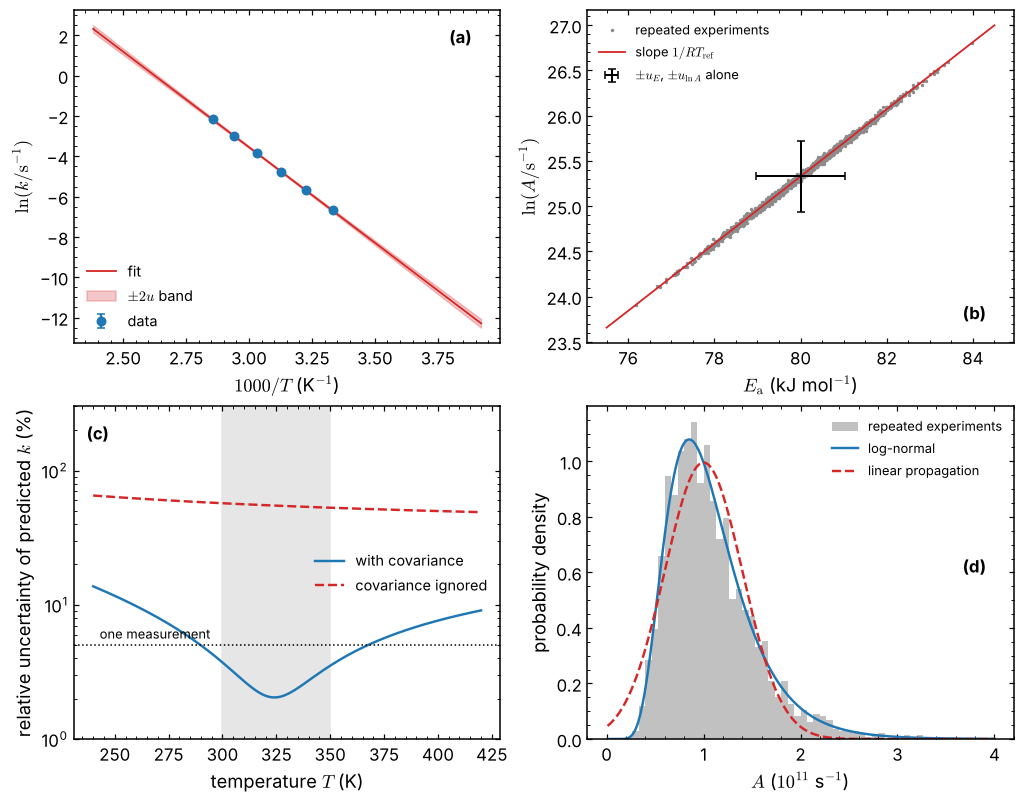

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(9.2, 7.2))

ax = axes[0, 0]
Tg = np.linspace(255, 420, 200)
yg, ug = fit.predict(1 / Tg)
ax.errorbar(1e3 / T, np.log(k), yerr=rel_k, fmt="o", color="C0", label="data")
ax.plot(1e3 / Tg, yg, "C3", lw=1.2, label="fit")
ax.fill_between(1e3 / Tg, yg - 2 * ug, yg + 2 * ug, color="C3", alpha=0.25, label=r"$\pm2u$ band")
ax.set_xlabel(r"$1000/T$ (K$^{-1}$)"); ax.set_ylabel(r"$\ln (k/\mathrm{s^{-1}})$")
ax.legend(loc="lower left"); ep.panel_label(ax, "(a)", x=0.88)

ax = axes[0, 1]
ax.plot(par[:, 0], par[:, 1], ".", ms=2.5, color="0.55", label="repeated experiments")
ee = np.linspace(75.5, 84.5, 10)
ax.plot(ee, np.log(A_true) + (ee - Ea_true / 1e3) * 1e3 / (R * T_ref), "C3-", lw=1.2,
        label=r"slope $1/RT_\mathrm{ref}$")
ax.errorbar(Ea_true / 1e3, np.log(A_true), xerr=u_Ea / 1e3, yerr=u_lnA, fmt="none", color="k",
            lw=1.3, zorder=5, label=r"$\pm u_{E}$, $\pm u_{\ln A}$ alone")
ax.set_xlabel(r"$E_\mathrm{a}$ (kJ mol$^{-1}$)"); ax.set_ylabel(r"$\ln (A/\mathrm{s^{-1}})$")
ax.legend(loc="upper left", fontsize=8.5); ep.panel_label(ax, "(b)", x=0.88, y=0.12)

ax = axes[1, 0]
Tg2 = np.linspace(240, 420, 200)
ax.semilogy(Tg2, u_lnk(Tg2) * 100, "C0", label="with covariance")
ax.semilogy(Tg2, u_lnk(Tg2, False) * 100, "C3--", label="covariance ignored")
ax.axvspan(T.min(), T.max(), color="0.9", zorder=0)
ax.axhline(rel_k * 100, color="k", ls=":", lw=1)
ax.text(243, rel_k * 100 * 1.12, "one measurement", fontsize=8.5)
ax.set_xlabel("temperature $T$ (K)"); ax.set_ylabel("relative uncertainty of predicted $k$ (%)")
ax.set_ylim(1, 300); ax.legend(loc="center right"); ep.panel_label(ax, "(c)")

ax = axes[1, 1]
A_rep = np.exp(par[:, 1]) / 1e11
ax.hist(A_rep, bins=np.linspace(0, 4, 61), density=True, color="0.6", alpha=0.6, label="repeated experiments")
g = np.linspace(0.01, 4, 400)
s_ln = par[:, 1].std(ddof=1)
ax.plot(g, np.exp(-0.5 * (np.log(g) / s_ln)**2) / (g * s_ln * np.sqrt(2 * np.pi)), "C0", label="log-normal")
ax.plot(g, np.exp(-0.5 * ((g - 1) / s_ln)**2) / (s_ln * np.sqrt(2 * np.pi)), "C3--", label="linear propagation")
ax.set_xlabel(r"$A$ ($10^{11}$ s$^{-1}$)"); ax.set_ylabel("probability density")
ax.legend(loc="upper right", fontsize=8.5); ep.panel_label(ax, "(d)", x=0.88, y=0.55)
plt.show()

**Panel (a)**: the Arrhenius plot. The uncertainty band of the line is
narrower than the symbols within the data and opens outside.

**Panel (b)**: the fitted pairs $(E_\mathrm{a}, \ln A)$ lie on a needle. Its
direction is no accident. Since every acceptable fit must pass through the
centroid of the data, $\ln A - E_\mathrm{a}/(RT_\text{ref}) = \ln k_\text{ref}$
is nearly fixed, so the pairs are confined to a line of slope
$1/(RT_\text{ref})$. The black cross, the two standard uncertainties quoted
separately, suggests a rectangle of possible values, of which almost all is
empty.

**Panel (c)**: the uncertainty of a predicted rate constant on a
logarithmic scale. With the covariance it dips to 2 % at the centre of the
data. Without it, it is about 50 % or more everywhere.

**Panel (d)**: the distribution of the fitted $A$ is skewed, with a tail to
large values, and is described by a log-normal distribution, not by the
symmetric curve from linear propagation.

### A warning about compensation plots

Suppose the 2000 points of panel (b) were not repetitions of one experiment
but results for 2000 related reactions, catalysts or solvents. A plot of
$\ln A$ against $E_\mathrm{a}$ would show a striking linear relation, and
it would be tempting to announce a *kinetic compensation effect* (or, for
equilibrium data, an enthalpy–entropy compensation) with an "isokinetic
temperature" given by the slope. Panel (b) shows that statistical error
alone produces exactly such a line, with an apparent isokinetic
temperature equal to the harmonic mean of the experimental temperatures.
This was pointed out by Krug, Hunter and Grieger in 1976. A compensation
line whose slope corresponds to the mean temperature of the measurements
is, until shown otherwise, an artefact of correlated errors. The safe test
is to plot the uncorrelated pair $(E_\mathrm{a}, \ln k_\text{ref})$ instead.

## Summary

* With constant relative uncertainty of $k$, fit $\ln k$ against $1/T$
  unweighted. Otherwise weight with $u_k/k$, or fit $k$ directly.
* $E_\mathrm{a}$ comes from the slope and is well determined. $\ln A$ is a
  long extrapolation and is not; $A$ should be quoted with a multiplicative
  uncertainty.
* $E_\mathrm{a}$ and $\ln A$ are correlated with $\rho \approx 0.999$.
  Predictions need the covariance; without it the uncertainty here is wrong
  by a factor of more than 25.
* Report $k$ at a reference temperature in the middle of the data together
  with $E_\mathrm{a}$. These two are uncorrelated.
* Linear relations between fitted $\ln A$ and $E_\mathrm{a}$ are produced
  by the error correlation alone.

## References

* R. R. Krug, W. G. Hunter and R. A. Grieger, "Enthalpy-entropy
  compensation. 1. Some fundamental statistical problems associated with the
  analysis of van't Hoff and Arrhenius data", *J. Phys. Chem.* **80**, 2335
  (1976).

## Exercises

1. Halve the temperature range (300 to 325 K, six points). What happens to
   $u_{E}$, to $u_{\ln A}$ and to the uncertainty of $k$ at 312 K? Which
   of these would you have predicted without calculation?
2. Compute the uncertainty of the *ratio* $k(350\ \mathrm K)/k(300\ \mathrm K)$
   from the fit. Which parameter does it depend on?
3. Replace the multiplicative noise by additive noise with standard
   deviation equal to 5 % of the *largest* rate constant. Compare the
   unweighted fit of $\ln k$, the weighted fit, and a nonlinear fit of $k$
   with `scipy.optimize.curve_fit`.
4. The Eyring equation, $k = (k_\mathrm{B}T/h)\,e^{\Delta S^\ddagger/R}e^{-\Delta H^\ddagger/RT}$,
   is analysed by plotting $\ln(k/T)$ against $1/T$. Fit the same data and
   find the correlation between $\Delta H^\ddagger$ and $\Delta S^\ddagger$.

---

**Previous:** [21. Chemical engineering: viscosity from a falling sphere](21_falling_sphere_viscosity.ipynb) &nbsp;·&nbsp; **Next:** [23. Molecular simulation: pressure and diffusion in a Lennard-Jones liquid](23_md_lennard_jones.ipynb)